## 1. Imports

In [2]:
import os
import glob
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.utils as vutils

print(torch.__version__)

2.11.0+cu130


## 2. Settings

In [3]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
image_size = 64
batch_size = 128
latent_dim = 100
num_images = 50000
epochs = 30
lr = 0.0002
beta1 = 0.5

print(device, image_size, batch_size, latent_dim, num_images, epochs)

cuda 64 128 100 50000 30


## 3. Load image paths

In [4]:
image_paths = sorted(glob.glob('/kaggle/input/**/*.jpg', recursive=True))
image_paths = image_paths[:num_images]

print(len(image_paths), image_paths[0])

50000 /kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba/000001.jpg


## 4. Preprocessing and DataLoader

In [5]:
transform = transforms.Compose([transforms.CenterCrop(148), transforms.Resize(image_size), transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])


class FaceDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert('RGB')
        return self.transform(image)


dataloader = DataLoader(FaceDataset(image_paths, transform), batch_size=batch_size, shuffle=True, num_workers=2, drop_last=True)
batch = next(iter(dataloader))

print(batch.shape, batch.min().item(), batch.max().item())

torch.Size([128, 3, 64, 64]) -1.0 1.0


## 5. Look at real faces

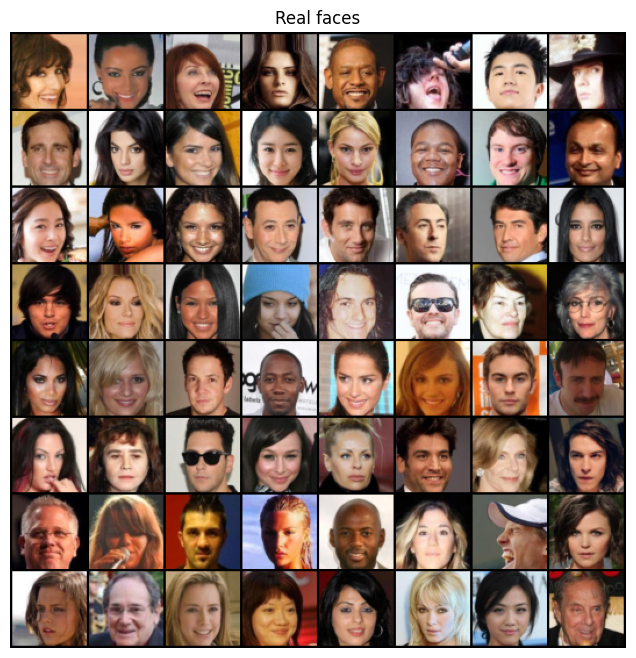

torch.Size([3, 530, 530])


In [6]:
grid = vutils.make_grid(batch[:64], padding=2, normalize=True)
plt.figure(figsize=(8, 8))
plt.axis('off')
plt.title('Real faces')
plt.imshow(grid.permute(1, 2, 0))
plt.show()

print(grid.shape)

## 6. Generator

In [7]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(nn.ConvTranspose2d(latent_dim, 512, 4, 1, 0, bias=False), nn.BatchNorm2d(512), nn.ReLU(True), nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False), nn.BatchNorm2d(256), nn.ReLU(True), nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True), nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(True), nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False), nn.Tanh())

    def forward(self, x):
        return self.model(x)


generator = Generator().to(device)
test_noise = torch.randn(4, latent_dim, 1, 1, device=device)

print(generator(test_noise).shape)

torch.Size([4, 3, 64, 64])


## 7. Discriminator

In [8]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(nn.Conv2d(3, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, inplace=True), nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True), nn.Conv2d(128, 256, 4, 2, 1, bias=False), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True), nn.Conv2d(256, 512, 4, 2, 1, bias=False), nn.BatchNorm2d(512), nn.LeakyReLU(0.2, inplace=True), nn.Conv2d(512, 1, 4, 1, 0, bias=False))

    def forward(self, x):
        return self.model(x).view(-1)


discriminator = Discriminator().to(device)

print(discriminator(torch.randn(4, 3, image_size, image_size, device=device)).shape)

torch.Size([4])


## 8. Weight initialization, losses and optimizers

In [10]:
def init_weights(layer):
    name = layer.__class__.__name__
    if 'Conv' in name:
        nn.init.normal_(layer.weight, 0.0, 0.02)
    elif 'BatchNorm' in name:
        nn.init.normal_(layer.weight, 1.0, 0.02)
        nn.init.constant_(layer.bias, 0)


generator.apply(init_weights)
discriminator.apply(init_weights)

criterion = nn.BCEWithLogitsLoss()
optimizer_g = optim.Adam(generator.parameters(), lr=lr, betas=(beta1, 0.999))
optimizer_d = optim.Adam(discriminator.parameters(), lr=lr, betas=(beta1, 0.999))
fixed_noise = torch.randn(64, latent_dim, 1, 1, device=device)

# real label is 0.9 instead of 1 so the discriminator does not become too confident
real_label = 0.9
fake_label = 0.0

print(sum(p.numel() for p in generator.parameters()), sum(p.numel() for p in discriminator.parameters()))

3576704 2765568


## 9. Training

In [11]:
os.makedirs('samples', exist_ok=True)
g_losses = []
d_losses = []
saved_epochs = []
saved_grids = []
steps = len(dataloader)

for epoch in range(1, epochs + 1):
    for real in dataloader:
        real = real.to(device)
        size = real.size(0)
        noise = torch.randn(size, latent_dim, 1, 1, device=device)
        fake = generator(noise)

        discriminator.zero_grad()
        loss_real = criterion(discriminator(real), torch.full((size,), real_label, device=device))
        # detach so the generator is not updated in the discriminator step
        loss_fake = criterion(discriminator(fake.detach()), torch.full((size,), fake_label, device=device))
        loss_d = loss_real + loss_fake
        loss_d.backward()
        optimizer_d.step()

        generator.zero_grad()
        loss_g = criterion(discriminator(fake), torch.ones(size, device=device))
        loss_g.backward()
        optimizer_g.step()

        g_losses.append(loss_g.item())
        d_losses.append(loss_d.item())

    print(f'Epoch {epoch}/{epochs}  D loss: {np.mean(d_losses[-steps:]):.4f}  G loss: {np.mean(g_losses[-steps:]):.4f}')

    if epoch == 1 or epoch % 5 == 0:
        with torch.no_grad():
            samples = generator(fixed_noise).cpu()
        vutils.save_image(samples, f'samples/epoch_{epoch}.png', normalize=True, nrow=8)
        saved_epochs.append(epoch)
        saved_grids.append(vutils.make_grid(samples, padding=2, normalize=True))

print('Training finished', len(g_losses))

Epoch 1/30  D loss: 0.8314  G loss: 6.9674
Epoch 2/30  D loss: 0.7420  G loss: 4.6493
Epoch 3/30  D loss: 0.7792  G loss: 4.2768
Epoch 4/30  D loss: 0.8122  G loss: 3.9854
Epoch 5/30  D loss: 0.7676  G loss: 3.8484
Epoch 6/30  D loss: 0.7798  G loss: 3.5272
Epoch 7/30  D loss: 0.8079  G loss: 3.2580
Epoch 8/30  D loss: 0.8572  G loss: 2.9135
Epoch 9/30  D loss: 0.8904  G loss: 2.7351
Epoch 10/30  D loss: 0.8685  G loss: 2.6807
Epoch 11/30  D loss: 0.8693  G loss: 2.6865
Epoch 12/30  D loss: 0.8551  G loss: 2.6553
Epoch 13/30  D loss: 0.8510  G loss: 2.6928
Epoch 14/30  D loss: 0.8971  G loss: 2.6078
Epoch 15/30  D loss: 0.8461  G loss: 2.6519
Epoch 16/30  D loss: 0.8489  G loss: 2.6127
Epoch 17/30  D loss: 0.8141  G loss: 2.7079
Epoch 18/30  D loss: 0.8571  G loss: 2.6626
Epoch 19/30  D loss: 0.8408  G loss: 2.7171
Epoch 20/30  D loss: 0.8405  G loss: 2.6733
Epoch 21/30  D loss: 0.8282  G loss: 2.6763
Epoch 22/30  D loss: 0.8484  G loss: 2.6761
Epoch 23/30  D loss: 0.8017  G loss: 2.75

## 10. Losses

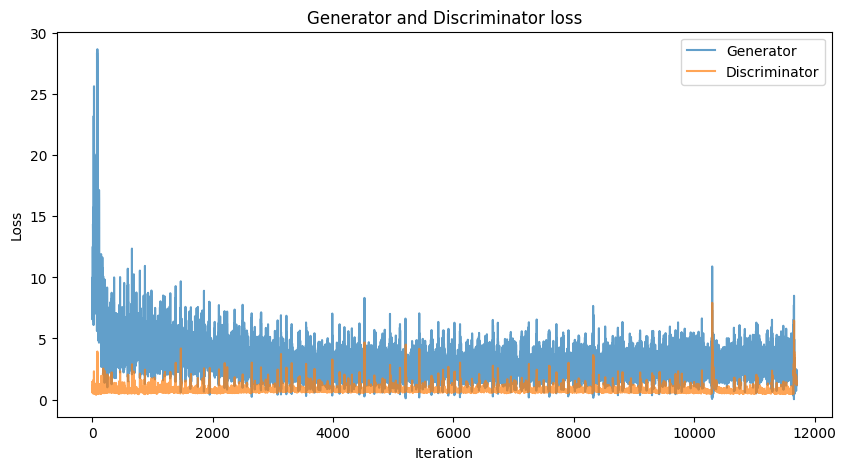

2.946118134417786 0.8533439743213165


In [12]:
plt.figure(figsize=(10, 5))
plt.plot(g_losses, label='Generator', alpha=0.7)
plt.plot(d_losses, label='Discriminator', alpha=0.7)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Generator and Discriminator loss')
plt.legend()
plt.show()

print(np.mean(g_losses[-steps:]), np.mean(d_losses[-steps:]))

## 11. Results over time

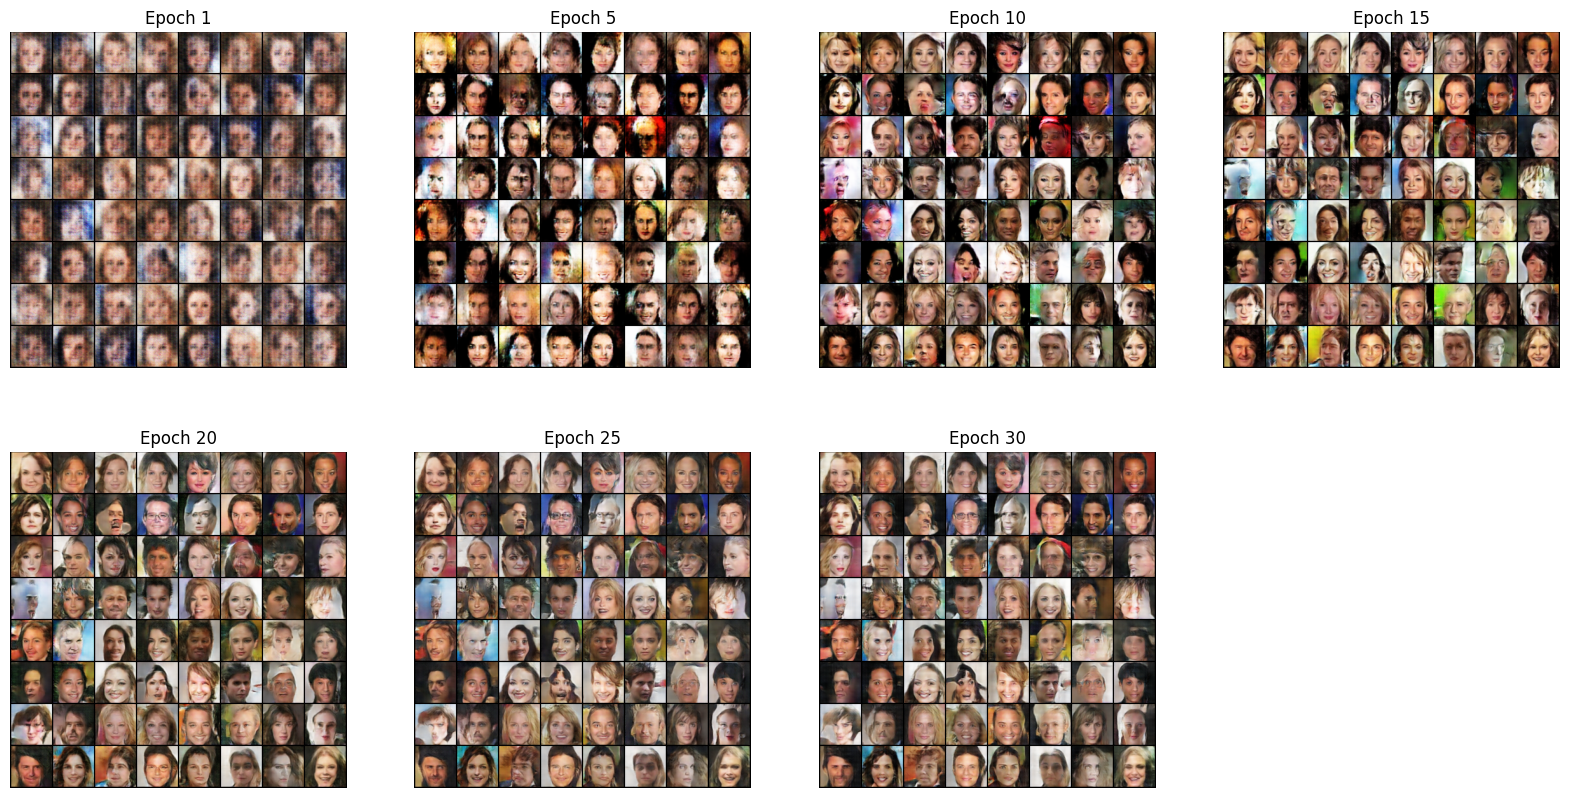

[1, 5, 10, 15, 20, 25, 30]


In [13]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for ax in axes:
    ax.axis('off')
for ax, ep, img in zip(axes, saved_epochs, saved_grids):
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(f'Epoch {ep}')
plt.show()

print(saved_epochs)

## 12. Final generated faces

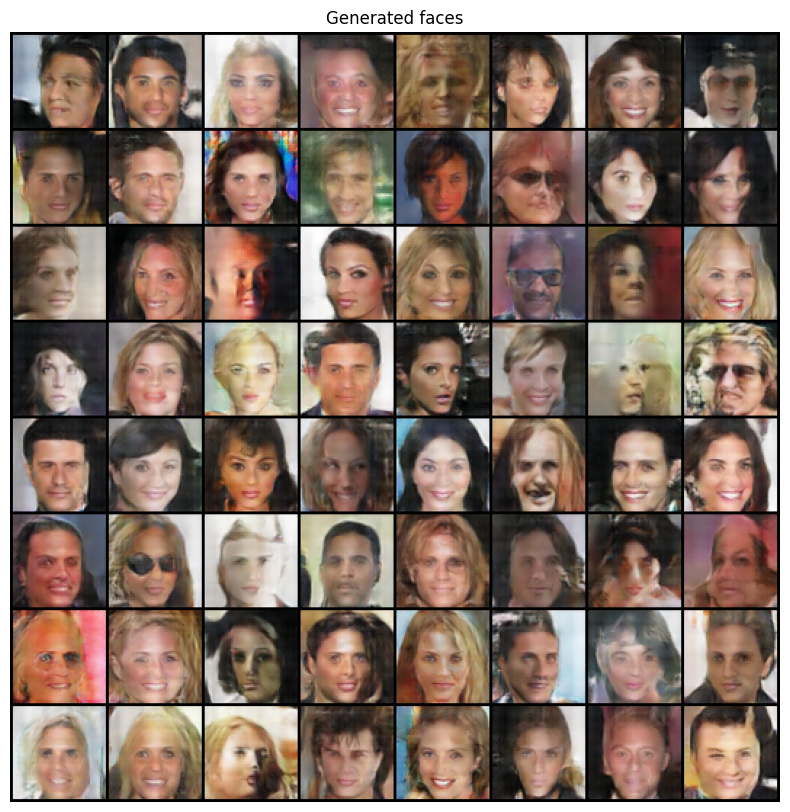

torch.Size([64, 3, 64, 64])


In [14]:
with torch.no_grad():
    final_faces = generator(torch.randn(64, latent_dim, 1, 1, device=device)).cpu()
final_grid = vutils.make_grid(final_faces, padding=2, normalize=True)
plt.figure(figsize=(10, 10))
plt.axis('off')
plt.title('Generated faces')
plt.imshow(final_grid.permute(1, 2, 0))
plt.show()
vutils.save_image(final_faces, 'samples/final_faces.png', normalize=True, nrow=8)
torch.save(generator.state_dict(), 'generator.pth')

print(final_faces.shape)

## 13. Real vs generated

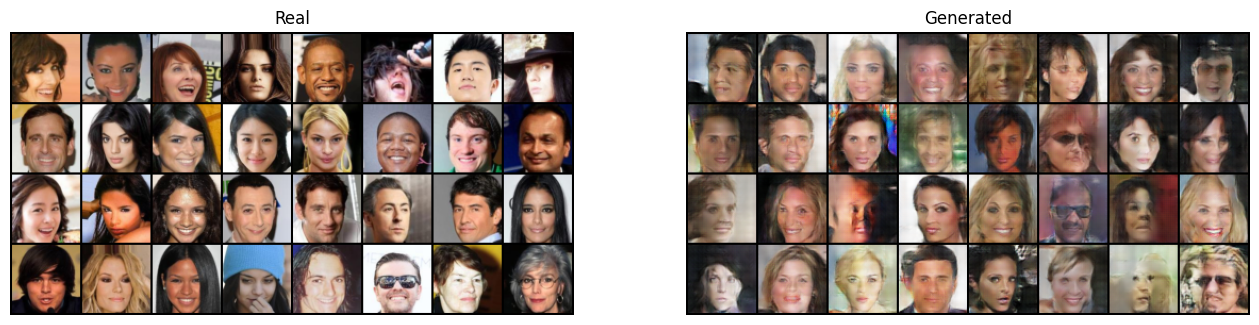

done


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(vutils.make_grid(batch[:32], padding=2, normalize=True, nrow=8).permute(1, 2, 0))
axes[0].set_title('Real')
axes[0].axis('off')
axes[1].imshow(vutils.make_grid(final_faces[:32], padding=2, normalize=True, nrow=8).permute(1, 2, 0))
axes[1].set_title('Generated')
axes[1].axis('off')
plt.show()

print('done')